In [ ]:

# AIML MINOR PROJECT 2

## Predict New York City Airbnb Prices

**Project Domain:** Machine Learning

**Algorithm:** Linear Regression

**Dataset:** New York City Airbnb Open Data

**Objective:** To analyze Airbnb listing information and build a Linear Regression model to predict listing prices.


Step 1.3 – Import Libraries and Upload Dataset

In [1]:

# Import required libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Upload the dataset
from google.colab import files

uploaded = files.upload()

# Read CSV file
df = pd.read_csv('AB_NYC_2019.csv')

print("Dataset successfully loaded!")


Saving AB_NYC_2019.csv.zip to AB_NYC_2019.csv.zip


FileNotFoundError: [Errno 2] No such file or directory: 'AB_NYC_2019.csv'

In [4]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Automatically detect uploaded filename
filename = list(uploaded.keys())[0]

# Read dataset
df = pd.read_csv(filename)

print("Dataset successfully loaded!")
print("File Name:", filename)
print("Dataset Shape:", df.shape)


Dataset successfully loaded!
File Name: AB_NYC_2019.csv.zip
Dataset Shape: (48895, 16)


. Step 1.4 – Inspect the Dataset

In [5]:

# Display first five records
print("First Five Rows:")
display(df.head())

# Check dataset dimensions
print("\nDataset Shape:")
print(df.shape)

# Display column names
print("\nColumn Names:")
print(df.columns.tolist())

# Check data types and non-null values
print("\nDataset Information:")
df.info()


First Five Rows:


,id,name,host_id,host_name,neighbourhood_group,neighbourhood,latitude,longitude,room_type,price,minimum_nights,number_of_reviews,last_review,reviews_per_month,calculated_host_listings_count,availability_365
0,2539,Clean & quiet apt home by the park,2787,John,Brooklyn,Kensington,40.64749,-73.97237,Private room,149,1,9,2018-10-19,0.21,6,365
1,2595,Skylit Midtown Castle,2845,Jennifer,Manhattan,Midtown,40.75362,-73.98377,Entire home/apt,225,1,45,2019-05-21,0.38,2,355
2,3647,THE VILLAGE OF HARLEM....NEW YORK !,4632,Elisabeth,Manhattan,Harlem,40.80902,-73.94190,Private room,150,3,0,NaN,NaN,1,365
3,3831,Cozy Entire Floor of Brownstone,4869,LisaRoxanne,Brooklyn,Clinton Hill,40.68514,-73.95976,Entire home/apt,89,1,270,2019-07-05,4.64,1,194
4,5022,Entire Apt: Spacious Studio/Loft by central park,7192,Laura,Manhattan,East Harlem,40.79851,-73.94399,Entire home/apt,80,10,9,2018-11-19,0.10,1,0



Dataset Shape:
(48895, 16)

Column Names:
['id', 'name', 'host_id', 'host_name', 'neighbourhood_group', 'neighbourhood', 'latitude', 'longitude', 'room_type', 'price', 'minimum_nights', 'number_of_reviews', 'last_review', 'reviews_per_month', 'calculated_host_listings_count', 'availability_365']

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 48895 entries, 0 to 48894
Data columns (total 16 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   id                              48895 non-null  int64  
 1   name                            48879 non-null  object 
 2   host_id                         48895 non-null  int64  
 3   host_name                       48874 non-null  object 
 4   neighbourhood_group             48895 non-null  object 
 5   neighbourhood                   48895 non-null  object 
 6   latitude                        48895 non-null  float64
 7   longitude        

Step 2.1 – Check missing values

In [6]:

# Check missing values in each column

missing_values = df.isnull().sum()

print("Missing Values in Each Column:")
print(missing_values)

# Calculate missing percentages

missing_percentage = (df.isnull().sum() / len(df)) * 100

print("\nMissing Value Percentage:")
print(missing_percentage.round(2))


Missing Values in Each Column:
id                                    0
name                                 16
host_id                               0
host_name                            21
neighbourhood_group                   0
neighbourhood                         0
latitude                              0
longitude                             0
room_type                             0
price                                 0
minimum_nights                        0
number_of_reviews                     0
last_review                       10052
reviews_per_month                 10052
calculated_host_listings_count        0
availability_365                      0
dtype: int64

Missing Value Percentage:
id                                 0.00
name                               0.03
host_id                            0.00
host_name                          0.04
neighbourhood_group                0.00
neighbourhood                      0.00
latitude                           0.00
longitude

Step 2.2 – Visualize missing values

In [ ]:

plt.figure(figsize=(12, 6))

sns.heatmap(df.isnull(),
            cbar=False,
            cmap='viridis')

plt.title("Missing Values in Airbnb Dataset")
plt.xlabel("Columns")
plt.ylabel("Records")

plt.show()


Step 2.3 – Investigate reviews_per_month

In [ ]:

# Check rows where reviews_per_month is missing

missing_reviews = df[df['reviews_per_month'].isnull()]

print("Missing reviews_per_month records:")
display(missing_reviews[['number_of_reviews',
                          'reviews_per_month']].head(10))

print("\nTotal missing records:",
      len(missing_reviews))

print("\nNumber of reviews in missing records:")
print(missing_reviews['number_of_reviews'].value_counts())


Step 2.4 – Handle missing values

In [ ]:

# Fill missing reviews_per_month with 0
df['reviews_per_month'] = df['reviews_per_month'].fillna(0)

# Drop last_review because it has many missing values
# and is not required for our selected model features

df = df.drop(columns=['last_review'])

# Drop irrelevant identifier and text columns

columns_to_drop = [
    'id',
    'name',
    'host_id',
    'host_name',
    'neighbourhood'
]

df = df.drop(columns=columns_to_drop)

print("Data cleaning completed!")
print("\nRemaining columns:")
print(df.columns.tolist())


Step 2.5 – Verify cleaning

In [12]:

print("Missing Values After Cleaning:")
print(df.isnull().sum())

print("\nFinal Dataset Shape:")
print(df.shape)

print("\nDataset Information:")
df.info()


Missing Values After Cleaning:
id                                    0
name                                 16
host_id                               0
host_name                            21
neighbourhood_group                   0
neighbourhood                         0
latitude                              0
longitude                             0
room_type                             0
price                                 0
minimum_nights                        0
number_of_reviews                     0
last_review                       10052
reviews_per_month                 10052
calculated_host_listings_count        0
availability_365                      0
dtype: int64

Final Dataset Shape:
(48895, 16)

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 48895 entries, 0 to 48894
Data columns (total 16 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   id                      

Step 2.4 – Handle missing values

In [13]:

# STEP 2: DATA CLEANING

# Fill missing monthly review values with zero
df['reviews_per_month'] = df['reviews_per_month'].fillna(0)

# Remove unnecessary columns
columns_to_drop = [
    'id',
    'name',
    'host_id',
    'host_name',
    'neighbourhood',
    'last_review'
]

df.drop(columns=columns_to_drop, inplace=True)

# Display cleaned dataset
print("DATA CLEANING SUCCESSFUL!")

print("\nFirst 5 Rows:")
display(df.head())

print("\nDataset Shape:")
print(df.shape)

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDataset Information:")
df.info()


DATA CLEANING SUCCESSFUL!

First 5 Rows:


,neighbourhood_group,latitude,longitude,room_type,price,minimum_nights,number_of_reviews,reviews_per_month,calculated_host_listings_count,availability_365
0,Brooklyn,40.64749,-73.97237,Private room,149,1,9,0.21,6,365
1,Manhattan,40.75362,-73.98377,Entire home/apt,225,1,45,0.38,2,355
2,Manhattan,40.80902,-73.94190,Private room,150,3,0,0.00,1,365
3,Brooklyn,40.68514,-73.95976,Entire home/apt,89,1,270,4.64,1,194
4,Manhattan,40.79851,-73.94399,Entire home/apt,80,10,9,0.10,1,0



Dataset Shape:
(48895, 10)

Missing Values:
neighbourhood_group               0
latitude                          0
longitude                         0
room_type                         0
price                             0
minimum_nights                    0
number_of_reviews                 0
reviews_per_month                 0
calculated_host_listings_count    0
availability_365                  0
dtype: int64

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 48895 entries, 0 to 48894
Data columns (total 10 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   neighbourhood_group             48895 non-null  object 
 1   latitude                        48895 non-null  float64
 2   longitude                       48895 non-null  float64
 3   room_type                       48895 non-null  object 
 4   price                           48895 non-null  int64  
 5   minimum_nights     

Step 3.1 – Understand outliers
An outlier is a value that is unusually high or low compared with most values in a dataset.

For example:
- Airbnb price = $100 per night: ordinary listing.
- Airbnb price = $10,000 per night: extreme listing.
- Minimum nights = 2: ordinary booking.
- Minimum nights = 365: long-term rental listing.
Step 3.2 – Visualize outliers

Current Dataset Shape: (48895, 10)

Statistical Summary:


,price,minimum_nights
count,48895.000000,48895.000000
mean,152.720687,7.029962
std,240.154170,20.510550
min,0.000000,1.000000
25%,69.000000,1.000000
50%,106.000000,3.000000
75%,175.000000,5.000000
max,10000.000000,1250.000000


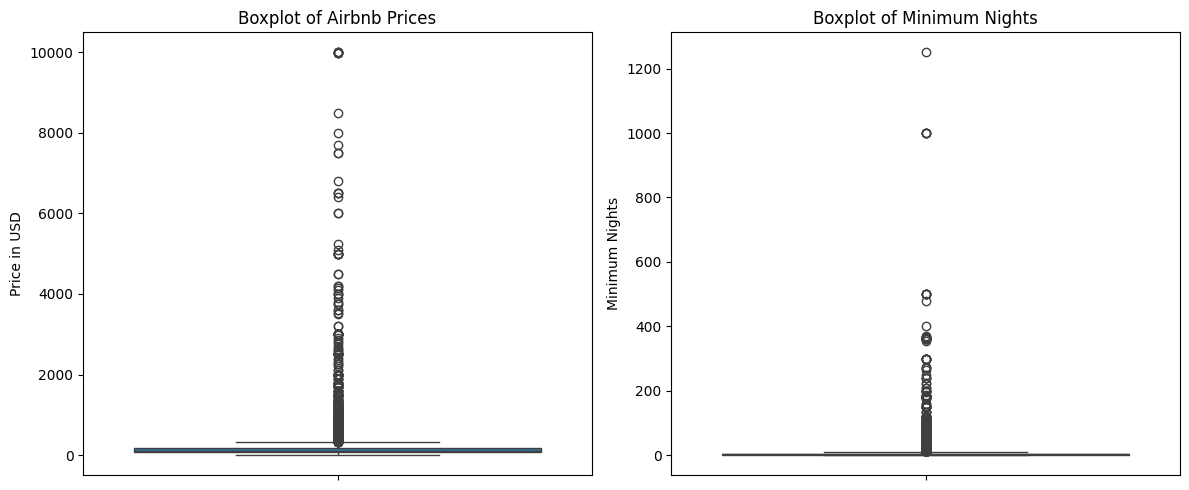

In [14]:

# STEP 3: OUTLIER IDENTIFICATION

# Check dataset shape
print("Current Dataset Shape:", df.shape)

# Statistical summary
print("\nStatistical Summary:")
display(df[['price', 'minimum_nights']].describe())

# Create boxplots
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
sns.boxplot(y=df['price'])
plt.title("Boxplot of Airbnb Prices")
plt.ylabel("Price in USD")

plt.subplot(1, 2, 2)
sns.boxplot(y=df['minimum_nights'])
plt.title("Boxplot of Minimum Nights")
plt.ylabel("Minimum Nights")

plt.tight_layout()
plt.show()


Step 3.3 – Calculate the 95th percentile

In [15]:

# Calculate 95th percentile

price_limit = df['price'].quantile(0.95)

nights_limit = df['minimum_nights'].quantile(0.95)

print("95th Percentile of Price:", price_limit)

print("95th Percentile of Minimum Nights:", nights_limit)

# Count extreme values

print("\nExtreme Price Records:",
      (df['price'] > price_limit).sum())

print("Extreme Minimum Nights Records:",
      (df['minimum_nights'] > nights_limit).sum())


95th Percentile of Price: 355.0
95th Percentile of Minimum Nights: 30.0

Extreme Price Records: 2441
Extreme Minimum Nights Records: 747


Step 3.4 – Treat outliers

In [16]:

# Remove records above the 95th percentile
# for price and minimum_nights

original_rows = len(df)

df = df[
    (df['price'] <= price_limit) &
    (df['minimum_nights'] <= nights_limit)
].copy()

removed_rows = original_rows - len(df)

print("OUTLIER TREATMENT COMPLETED")

print("Original Records:", original_rows)
print("Removed Records:", removed_rows)
print("Remaining Records:", len(df))

print("\nNew Dataset Shape:", df.shape)


OUTLIER TREATMENT COMPLETED
Original Records: 48895
Removed Records: 3136
Remaining Records: 45759

New Dataset Shape: (45759, 10)


This uses trimming rather than capping: records above either threshold are removed.
Step 3.5 – Verify the results

Price Statistics:
count    45759.000000
mean       122.515024
std         71.966885
min          0.000000
25%         65.000000
50%        100.000000
75%        160.000000
max        355.000000
Name: price, dtype: float64

Minimum Nights Statistics:
count    45759.000000
mean         5.557836
std          8.177057
min          1.000000
25%          1.000000
50%          2.000000
75%          5.000000
max         30.000000
Name: minimum_nights, dtype: float64


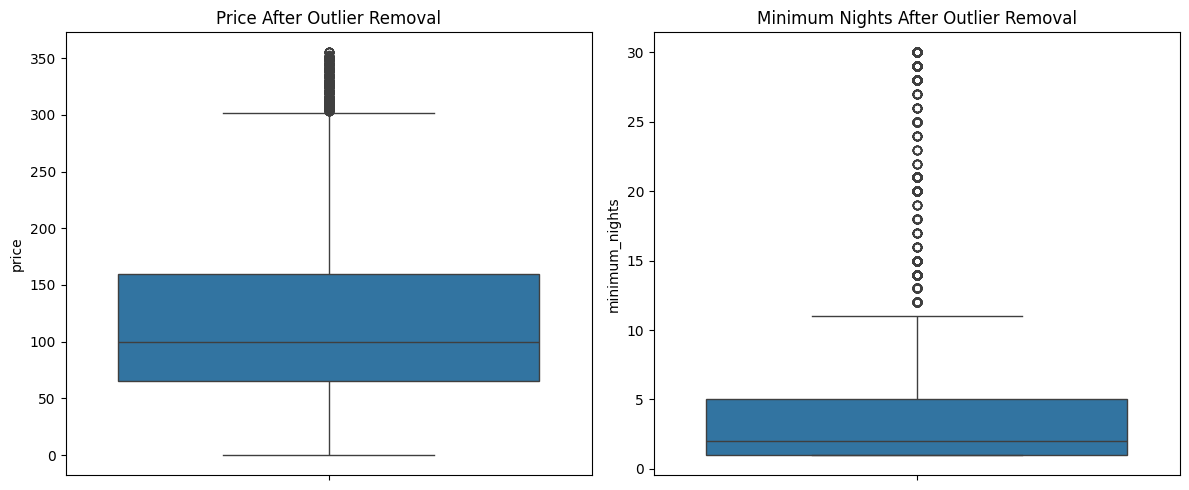

In [17]:

# Check the cleaned price and minimum nights

print("Price Statistics:")
print(df['price'].describe())

print("\nMinimum Nights Statistics:")
print(df['minimum_nights'].describe())

# Visualize after outlier treatment

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
sns.boxplot(y=df['price'])
plt.title("Price After Outlier Removal")

plt.subplot(1, 2, 2)
sns.boxplot(y=df['minimum_nights'])
plt.title("Minimum Nights After Outlier Removal")

plt.tight_layout()
plt.show()


In this step, I identified extreme values in the Airbnb dataset using boxplots and statistical analysis. I calculated the 95th percentile for the price and minimum_nights columns. Records exceeding these thresholds were removed to reduce the influence of unusually expensive listings and very long minimum-stay requirements. This helped prepare the dataset for Linear Regression.

Step 4 – Feature Selection & Categorical Encoding

Step 4.1 – Check categorical columns

In [ ]:

# STEP 4: FEATURE SELECTION

print("Unique Neighbourhood Groups:")
print(df['neighbourhood_group'].unique())

print("\nNumber of Neighbourhood Groups:")
print(df['neighbourhood_group'].nunique())

print("\nUnique Room Types:")
print(df['room_type'].unique())

print("\nNumber of Room Types:")
print(df['room_type'].nunique())


This will show us the different categories in your dataset.
Step 4.2 – Apply One-Hot Encoding

In [19]:

# STEP 4.2: ONE-HOT ENCODING

# Convert categorical columns into numerical format

df = pd.get_dummies(
    df,
    columns=['neighbourhood_group', 'room_type'],
    drop_first=True,
    dtype=int
)

print("ONE-HOT ENCODING COMPLETED!")

print("\nUpdated Dataset:")
display(df.head())

print("\nUpdated Dataset Shape:")
print(df.shape)

print("\nUpdated Column Names:")
print(df.columns.tolist())


ONE-HOT ENCODING COMPLETED!

Updated Dataset:


,latitude,longitude,price,minimum_nights,number_of_reviews,reviews_per_month,calculated_host_listings_count,availability_365,neighbourhood_group_Brooklyn,neighbourhood_group_Manhattan,neighbourhood_group_Queens,neighbourhood_group_Staten Island,room_type_Private room,room_type_Shared room
0,40.64749,-73.97237,149,1,9,0.21,6,365,1,0,0,0,1,0
1,40.75362,-73.98377,225,1,45,0.38,2,355,0,1,0,0,0,0
2,40.80902,-73.94190,150,3,0,0.00,1,365,0,1,0,0,1,0
3,40.68514,-73.95976,89,1,270,4.64,1,194,1,0,0,0,0,0
4,40.79851,-73.94399,80,10,9,0.10,1,0,0,1,0,0,0,0



Updated Dataset Shape:
(45759, 14)

Updated Column Names:
['latitude', 'longitude', 'price', 'minimum_nights', 'number_of_reviews', 'reviews_per_month', 'calculated_host_listings_count', 'availability_365', 'neighbourhood_group_Brooklyn', 'neighbourhood_group_Manhattan', 'neighbourhood_group_Queens', 'neighbourhood_group_Staten Island', 'room_type_Private room', 'room_type_Shared room']


Step 4.3 – Verify numerical data

In [18]:

# Check data types

print("Dataset Data Types:")
print(df.dtypes)

# Check for remaining categorical columns

print("\nCategorical Columns:")
print(df.select_dtypes(include=['object']).columns.tolist())


Dataset Data Types:
neighbourhood_group                object
latitude                          float64
longitude                         float64
room_type                          object
price                               int64
minimum_nights                      int64
number_of_reviews                   int64
reviews_per_month                 float64
calculated_host_listings_count      int64
availability_365                    int64
dtype: object

Categorical Columns:
['neighbourhood_group', 'room_type']


Step 5 – Feature-Target Separation & Train-Test Split

Step 5.1 – Separate X and y

In [20]:

# STEP 5: FEATURE-TARGET SEPARATION

# Independent variables
X = df.drop('price', axis=1)

# Dependent variable
y = df['price']

print("FEATURES (X)")
display(X.head())

print("\nTARGET (y)")
display(y.head())

print("\nFeatures Shape:", X.shape)
print("Target Shape:", y.shape)


FEATURES (X)


,latitude,longitude,minimum_nights,number_of_reviews,reviews_per_month,calculated_host_listings_count,availability_365,neighbourhood_group_Brooklyn,neighbourhood_group_Manhattan,neighbourhood_group_Queens,neighbourhood_group_Staten Island,room_type_Private room,room_type_Shared room
0,40.64749,-73.97237,1,9,0.21,6,365,1,0,0,0,1,0
1,40.75362,-73.98377,1,45,0.38,2,355,0,1,0,0,0,0
2,40.80902,-73.94190,3,0,0.00,1,365,0,1,0,0,1,0
3,40.68514,-73.95976,1,270,4.64,1,194,1,0,0,0,0,0
4,40.79851,-73.94399,10,9,0.10,1,0,0,1,0,0,0,0



TARGET (y)


,price
0,149
1,225
2,150
3,89
4,80



Features Shape: (45759, 13)
Target Shape: (45759,)


Understanding:
- X contains all information used to predict the Airbnb price.
- y contains the actual Airbnb prices that we want to predict.

Step 5.2 – Split the dataset
We will use an 80:20 split.

In [21]:

# Import train_test_split

from sklearn.model_selection import train_test_split

# Split dataset into training and testing sets

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("DATASET SPLIT SUCCESSFUL!")

print("\nTraining Features:", X_train.shape)
print("Testing Features:", X_test.shape)

print("\nTraining Target:", y_train.shape)
print("Testing Target:", y_test.shape)


DATASET SPLIT SUCCESSFUL!

Training Features: (36607, 13)
Testing Features: (9152, 13)

Training Target: (36607,)
Testing Target: (9152,)


Step 5.3 – Verify the split

In [22]:

print("Total Records:", len(df))
print("Training Records:", len(X_train))
print("Testing Records:", len(X_test))

print("\nTraining Percentage:",
      round(len(X_train)/len(df)*100, 2), "%")

print("Testing Percentage:",
      round(len(X_test)/len(df)*100, 2), "%")


Total Records: 45759
Training Records: 36607
Testing Records: 9152

Training Percentage: 80.0 %
Testing Percentage: 20.0 %


In this step, I separated the dataset into independent variables (X) and a dependent variable (y). The price column was selected as the target variable because the main objective is to predict Airbnb listing prices. I divided the dataset into 80% training data and 20% testing data using the train_test_split function. I used random_state=42 to ensure reproducibility.

STEP 6 – Linear Regression Model Training

Objective: Train a Linear Regression model using your Airbnb dataset to predict the price of rental properties in New York City.

Step 6.1 – Import Linear Regression

In [26]:

# STEP 6: LINEAR REGRESSION MODEL

# Import Linear Regression
from sklearn.linear_model import LinearRegression

print("Linear Regression imported successfully!")


Linear Regression imported successfully!


Step 6.2 – Create the model

In [27]:

# Create Linear Regression model

model = LinearRegression()

print("Linear Regression Model Created Successfully!")


Linear Regression Model Created Successfully!


LinearRegression() creates a machine learning model that learns the relationship between independent variables (X) and Airbnb prices (y).

Step 6.3 – Train the model

In [28]:

# Train the Linear Regression model

model.fit(X_train, y_train)

print("MODEL TRAINING COMPLETED SUCCESSFULLY!")


MODEL TRAINING COMPLETED SUCCESSFULLY!


Explanation:
- X_train contains 80% of your training features.
- y_train contains the actual Airbnb prices.
- fit() teaches the model the relationship between the features and prices

Step 6.4 – Make predictions

In [29]:

# Predict prices using test data

y_pred = model.predict(X_test)

print("PRICE PREDICTION COMPLETED!")

print("\nFirst 10 Predicted Prices:")
print(y_pred[:10])

print("\nFirst 10 Actual Prices:")
print(y_test.iloc[:10].values)


PRICE PREDICTION COMPLETED!

First 10 Predicted Prices:
[173.31999192 157.35088508 173.11463763 182.65747453 186.31011596
 165.57173509 128.75527424  59.73992377 191.65680481  99.05073498]

First 10 Actual Prices:
[132 250 350 250 199 139 150  55 184 129]


Step 6.5 – Compare actual and predicted prices

In [30]:

# Compare actual and predicted prices

comparison = pd.DataFrame({
    'Actual Price': y_test.values[:10],
    'Predicted Price': y_pred[:10]
})

print("ACTUAL VS PREDICTED PRICES")
display(comparison.round(2))


ACTUAL VS PREDICTED PRICES


,Actual Price,Predicted Price
0,132,173.32
1,250,157.35
2,350,173.11
3,250,182.66
4,199,186.31
5,139,165.57
6,150,128.76
7,55,59.74
8,184,191.66
9,129,99.05


Explanation:
In this step, I developed a Linear Regression model using the Scikit-learn library. The model was trained using the training dataset containing 80% of the available records. The fit() function was used to train the model by identifying relationships between the independent variables and the target variable (price). After training, predictions were generated using the testing dataset.

STEP 7 - Model Evaluation
Linear Regression – Performance Evaluation
We will calculate four important evaluation metrics:
1. R² Score
2. Mean Absolute Error (MAE)
3. Mean Squared Error (MSE)
4. Root Mean Squared Error (RMSE)

STEP 7 – Model Evaluation

We will calculate four important evaluation metrics:
1. R² Score
2. Mean Absolute Error (MAE)
3. Mean Squared Error (MSE)
4. Root Mean Squared Error (RMSE)
Step 7.1 – Import evaluation metrics

In [31]:

# STEP 7: MODEL EVALUATION

from sklearn.metrics import (
    r2_score,
    mean_absolute_error,
    mean_squared_error
)

print("Evaluation metrics imported successfully!")


Evaluation metrics imported successfully!


Step 7.2 – Calculate R² Score

In [32]:

# Calculate R2 Score

r2 = r2_score(y_test, y_pred)

print("R2 Score:", round(r2, 4))
print("R2 Score in Percentage:", round(r2 * 100, 2), "%")


R2 Score: 0.4708
R2 Score in Percentage: 47.08 %


Step 7.3 – Calculate MAE

Calculate MAE
MAE measures the average absolute difference between actual and predicted prices.

In [33]:

# Calculate Mean Absolute Error

mae = mean_absolute_error(y_test, y_pred)

print("Mean Absolute Error (MAE):", round(mae, 2))


Mean Absolute Error (MAE): 38.54


Step 7.4 – Calculate MSE


MSE calculates the average squared prediction error.

In [34]:

# Calculate Mean Squared Error

mse = mean_squared_error(y_test, y_pred)

print("Mean Squared Error (MSE):", round(mse, 2))


Mean Squared Error (MSE): 2834.96


Step 7.5 – Calculate RMSE
RMSE measures prediction error in the same unit as the target variable (USD).

In [36]:

# Calculate Root Mean Squared Error

rmse = np.sqrt(mse)

print("Root Mean Squared Error (RMSE):", round(rmse, 2))


Root Mean Squared Error (RMSE): 53.24


Step 7.6 – Display all evaluation metrics together:

In [37]:

# Final Model Performance Report

evaluation_results = pd.DataFrame({
    'Evaluation Metric': ['R2 Score', 'MAE', 'MSE', 'RMSE'],
    'Value': [r2, mae, mse, rmse]
})

print("FINAL LINEAR REGRESSION MODEL PERFORMANCE")

display(evaluation_results.round(4))


FINAL LINEAR REGRESSION MODEL PERFORMANCE


,Evaluation Metric,Value
0,R2 Score,0.4708
1,MAE,38.5409
2,MSE,2834.9594
3,RMSE,53.2443


The performance of the Linear Regression model was evaluated using R² Score, Mean Absolute Error, Mean Squared Error and Root Mean Squared Error. These metrics were used to understand how accurately the model predicts Airbnb listing prices. The R² score measures the explained variation, while MAE, MSE and RMSE measure prediction errors.

STEP 8 – Actual vs Predicted Price Visualization
Now we will visually compare the actual Airbnb prices with the prices predicted by our Linear Regression model.

Step 8.1 – Create a scatter plot

STEP 8 – Actual vs Predicted Price Visualization
Now we will visually compare the actual Airbnb prices with the prices predicted by our Linear Regression model.
Step 8.1 – Create a scatter plot

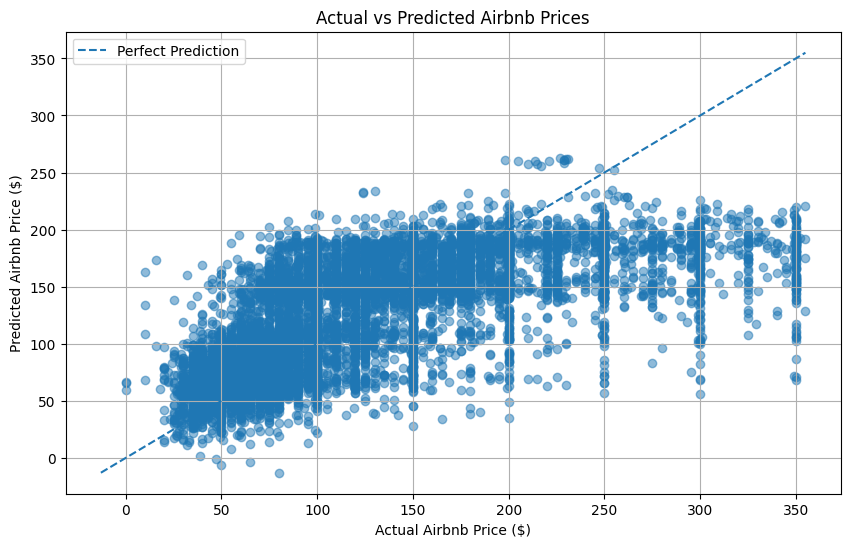

In [42]:

# STEP 8: ACTUAL VS PREDICTED PRICE VISUALIZATION

plt.figure(figsize=(10, 6))

plt.scatter(
    y_test,
    y_pred,
    alpha=0.5
)

# Perfect prediction reference line
min_value = min(y_test.min(), y_pred.min())
max_value = max(y_test.max(), y_pred.max())

plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    linestyle='--',
    label='Perfect Prediction'
)

plt.xlabel("Actual Airbnb Price ($)")
plt.ylabel("Predicted Airbnb Price ($)")

plt.title("Actual vs Predicted Airbnb Prices")

plt.legend()
plt.grid(True)

plt.show()


X-axis represents actual prices.



Y-axis represents predicted prices.



The diagonal line represents perfect predictions.



Points closer to the diagonal indicate more accurate predictions.

Step 8.3 – Write the observation


### Observation: Actual vs Predicted Prices

The scatter plot compares the actual Airbnb listing prices
with the prices predicted by the Linear Regression model.

The points are distributed around the reference line,
but several predictions show noticeable differences
from the actual prices.

This indicates that the model captures some of the
relationship between the input features and Airbnb prices,
although its prediction accuracy can be improved.


STEP 9 – Residual Analysis
This is our next major step.

We will:
- Calculate residual errors.
- Create a residual distribution plot.
- Create a residual vs predicted price plot.
- Understand whether prediction errors are randomly distributed.

\[
Residual = Actual\ Price - Predicted\ Price
\]

In [43]:

# STEP 9: RESIDUAL ANALYSIS

# Calculate residuals
residuals = y_test - y_pred

print("RESIDUALS CALCULATED SUCCESSFULLY!")

print("\nFirst 10 Residual Values:")
print(residuals.head(10))


RESIDUALS CALCULATED SUCCESSFULLY!

First 10 Residual Values:
15403    -41.319992
25339     92.649115
17177    176.885362
39544     67.342525
16658     12.689884
27465    -26.571735
16740     21.244726
25369     -4.739924
32889     -7.656805
30769     29.949265
Name: price, dtype: float64


In [ ]:
Step 9.2 – Create Residual Distribution Plot
This graph helps us understand the distribution of prediction errors.

Step 9.2 – Create Residual Distribution Plot
This graph helps us understand the distribution of prediction errors.

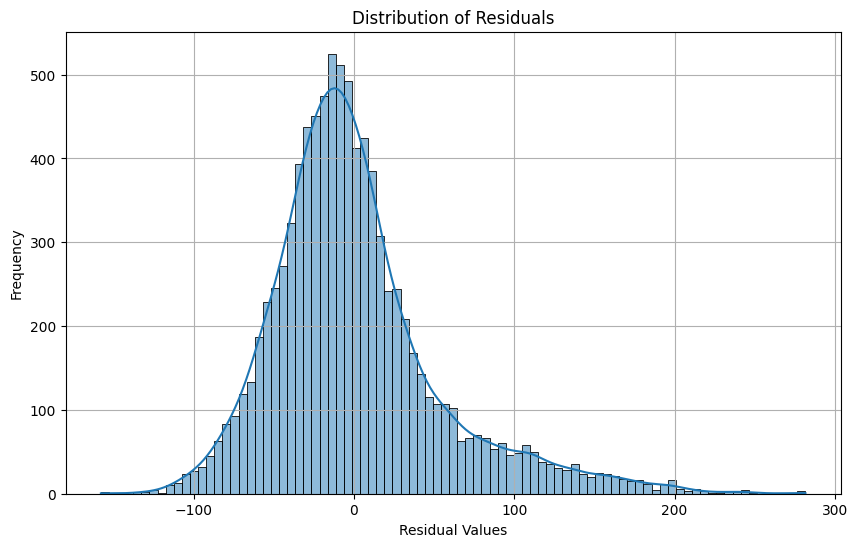

In [44]:

# Residual Distribution Plot

plt.figure(figsize=(10, 6))

sns.histplot(residuals, kde=True)

plt.title("Distribution of Residuals")
plt.xlabel("Residual Values")
plt.ylabel("Frequency")

plt.grid(True)
plt.show()


What to observe:
- Whether residuals are distributed around zero.
- Whether the distribution is approximately symmetric.
- Whether there are unusually large errors.

Step 9.3 –Residuals vs Predicted Values
This is one of the most important diagnostic graphs.

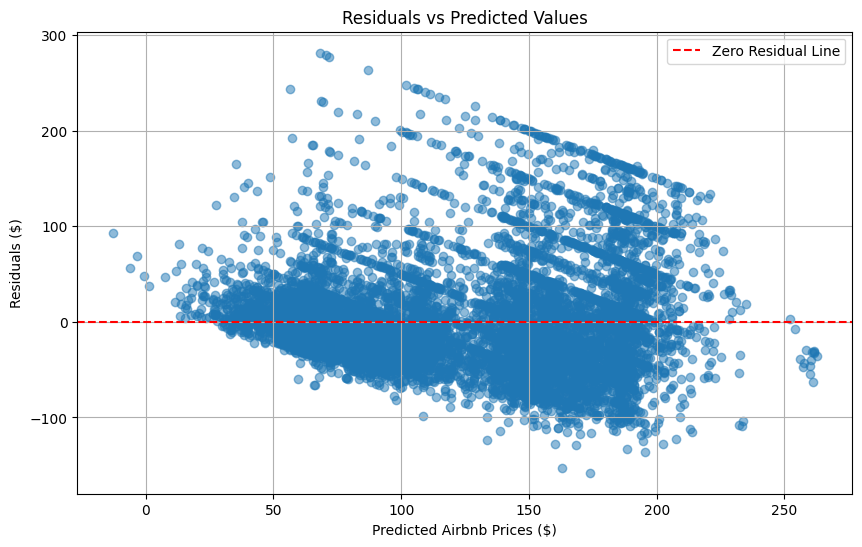

In [45]:

# Residuals vs Predicted Values Plot

plt.figure(figsize=(10, 6))

plt.scatter(y_pred, residuals, alpha=0.5)

plt.axhline(
    y=0,
    color='red',
    linestyle='--',
    label='Zero Residual Line'
)

plt.xlabel("Predicted Airbnb Prices ($)")
plt.ylabel("Residuals ($)")

plt.title("Residuals vs Predicted Values")

plt.legend()
plt.grid(True)
plt.show()


What to observe:
- Randomly scattered points around zero are generally desirable.
- A curved pattern may indicate non-linearity.
- A funnel shape may indicate unequal error variance.
- Large isolated points indicate unusually large prediction errors.

Step 9.4 – Create a Residual Comparison Table

In [46]:

# Actual, Predicted and Residual Comparison

residual_comparison = pd.DataFrame({
    'Actual Price': y_test.values[:10],
    'Predicted Price': y_pred[:10],
    'Residual': residuals.values[:10]
})

print("RESIDUAL ANALYSIS TABLE")

display(residual_comparison.round(2))


RESIDUAL ANALYSIS TABLE


,Actual Price,Predicted Price,Residual
0,132,173.32,-41.32
1,250,157.35,92.65
2,350,173.11,176.89
3,250,182.66,67.34
4,199,186.31,12.69
5,139,165.57,-26.57
6,150,128.76,21.24
7,55,59.74,-4.74
8,184,191.66,-7.66
9,129,99.05,29.95


Step 9.5: Calculate Mean Residual

In [47]:

# Calculate mean residual

mean_residual = residuals.mean()

print("Mean Residual:", round(mean_residual, 4))

print("\nMinimum Residual:", round(residuals.min(), 2))

print("Maximum Residual:", round(residuals.max(), 2))


Mean Residual: 1.0633

Minimum Residual: -157.79
Maximum Residual: 281.62





Explanation

Residual analysis was performed to examine the
prediction errors of the Linear Regression model.

Residuals were calculated by subtracting predicted
prices from actual Airbnb prices.

A residual distribution plot was created to
understand the distribution of errors.

A residuals vs predicted values plot was also
generated to identify possible patterns in the
prediction errors.

These visualizations help evaluate the assumptions
and limitations of the Linear Regression model.


STEP 10 – Conclusion


# STEP 10: FINAL CONCLUSION

## Conclusion

In this project, I performed Exploratory Data Analysis
and developed a Machine Learning model to predict
New York City Airbnb listing prices using Linear Regression.

Initially, I explored the Airbnb dataset and examined
its structure, features, and missing values.

Data cleaning was performed by handling missing values
and removing unnecessary columns. Outliers were identified
using the 95th percentile method.

Categorical variables were converted into numerical
values using One-Hot Encoding.

The cleaned dataset was divided into 80% training
data and 20% testing data.

A Linear Regression model was trained using Scikit-learn
to predict Airbnb listing prices.

The model achieved the following evaluation results:

- R2 Score: 0.4708
- MAE: 38.5409
- MSE: 2834.9594
- RMSE: 53.2443

The R2 score indicates that the model explains
approximately 47.08% of the variation in Airbnb prices.

Residual analysis was also performed to understand
the prediction errors and evaluate model behaviour.

Overall, this project helped me understand the
complete Machine Learning workflow, including
data preprocessing, feature selection, model training,
prediction, evaluation, and residual analysis.

The Linear Regression model provides a useful baseline
for Airbnb price prediction, although its accuracy
can be improved using more advanced regression
algorithms and additional feature engineering.



# FINAL PROJECT RESULTS

final_results = pd.DataFrame({
    'Metric': ['R2 Score', 'MAE', 'MSE', 'RMSE'],
    'Result': [r2, mae, mse, rmse]
})

print("AIRBNB PRICE PREDICTION - FINAL RESULTS")

display(final_results.round(4))


Step 10.3 – Print project information

In [48]:

print("PROJECT: AIRBNB PRICE PREDICTION")

print("\nAlgorithm: Linear Regression")

print("Original Dataset Records: 48895")

print("Records After Outlier Treatment:", len(df))

print("Number of Features:", X.shape[1])

print("Training Records:", len(X_train))

print("Testing Records:", len(X_test))

print("\nModel R2 Score:", round(r2, 4))

print("\nPROJECT COMPLETED SUCCESSFULLY!")


PROJECT: AIRBNB PRICE PREDICTION

Algorithm: Linear Regression
Original Dataset Records: 48895
Records After Outlier Treatment: 45759
Number of Features: 13
Training Records: 36607
Testing Records: 9152

Model R2 Score: 0.4708

PROJECT COMPLETED SUCCESSFULLY!


In [49]:

# FINAL PROJECT SUMMARY

print("=" * 55)
print("AIRBNB PRICE PREDICTION PROJECT")
print("=" * 55)

print("\nDataset Information")
print("Original Records: 48895")
print("Final Records:", len(df))
print("Final Columns:", df.shape[1])

print("\nModel Information")
print("Algorithm: Linear Regression")
print("Training Records:", len(X_train))
print("Testing Records:", len(X_test))

print("\nModel Evaluation")
print("R2 Score:", round(r2, 4))
print("MAE:", round(mae, 4))
print("MSE:", round(mse, 4))
print("RMSE:", round(rmse, 4))

print("\nPROJECT COMPLETED SUCCESSFULLY!")
print("=" * 55)


AIRBNB PRICE PREDICTION PROJECT

Dataset Information
Original Records: 48895
Final Records: 45759
Final Columns: 14

Model Information
Algorithm: Linear Regression
Training Records: 36607
Testing Records: 9152

Model Evaluation
R2 Score: 0.4708
MAE: 38.5409
MSE: 2834.9594
RMSE: 53.2443

PROJECT COMPLETED SUCCESSFULLY!
